In [43]:
import os
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.metrics import confusion_matrix, classification_report

# Activation functions

In [31]:
def relu(x):
    return np.maximum(0, x)
def relu_derivative(x):
    return np.where(x > 0, 1, 0)
def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=1 , keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

## Class MultiClassNeuralNetwork

In [32]:
class MultiClassNeuralNetwork:

    def __init__(self, layer_sizes, learning_rate=0.01):

        self.layer_sizes = layer_sizes
        self.learning_rate = learning_rate

        self.weights = []
        self.biases = []

        np.random.seed(42)

        for i in range(len(layer_sizes) - 1):

            w = np.random.randn(layer_sizes[i],layer_sizes[i + 1]) * 0.01

            b = np.zeros((1, layer_sizes[i + 1]))

            self.weights.append(w)
            self.biases.append(b)


    def forward(self, X):

        self.activations = [X]
        self.z_values = []

        # Hidden layers
        for i in range(len(self.weights) - 1):

            z = (self.activations[-1]@ self.weights[i]+ self.biases[i])

            self.z_values.append(z)

            self.activations.append(
                relu(z)
            )

        # Output layer
        z = (self.activations[-1]@ self.weights[-1]+ self.biases[-1])

        self.z_values.append(z)

        output = softmax(z)

        self.activations.append(output)

        return output


    def compute_loss(self, y_true, y_pred):

        y_pred = np.clip(y_pred,1e-15,1 - 1e-15)

        loss = -np.mean(np.sum(y_true * np.log(y_pred),axis=1))

        return loss


    def compute_accuracy(self, y_true, y_pred):

        predictions = np.argmax(y_pred,axis=1)

        true_labels = np.argmax(y_true,axis=1)

        accuracy = np.mean(predictions == true_labels)

        return accuracy


    def backward(self, X, y, outputs):

        m = X.shape[0]

        self.d_weights = [None] * len(self.weights)
        self.d_biases = [None] * len(self.biases)

        # Output layer
        dZ = outputs - y

        self.d_weights[-1] = (self.activations[-2].T @ dZ) / m

        self.d_biases[-1] = (np.sum(dZ,axis=0,keepdims=True)) / m

        # Hidden layers
        for i in range(len(self.weights) - 2,-1,-1):

            dZ = (dZ @ self.weights[i + 1].T) * relu_derivative(self.z_values[i])

            self.d_weights[i] = (self.activations[i].T @ dZ) / m

            self.d_biases[i] = (np.sum(dZ,axis=0,keepdims=True)) / m

        # Update parameters
        for i in range(len(self.weights)):

            self.weights[i] -= (self.learning_rate* self.d_weights[i])

            self.biases[i] -= (self.learning_rate* self.d_biases[i])


    def train(
        self,
        X,
        y,
        X_val,
        y_val,
        epochs,
        batch_size
    ):

        train_losses = []
        val_losses = []

        train_accuracies = []
        val_accuracies = []

        for epoch in range(epochs):

            # Shuffle
            indices = np.random.permutation(
                X.shape[0]
            )

            X_shuffled = X[indices]
            y_shuffled = y[indices]

            epoch_loss = 0

            # Mini-batch training
            for i in range(
                0,
                X.shape[0],
                batch_size
            ):

                X_batch = X_shuffled[
                    i:i + batch_size
                ]

                y_batch = y_shuffled[
                    i:i + batch_size
                ]

                outputs = self.forward(
                    X_batch
                )

                epoch_loss += self.compute_loss(
                    y_batch,
                    outputs
                )

                self.backward(
                    X_batch,
                    y_batch,
                    outputs
                )

            # Train metrics
            train_loss = (
                epoch_loss
                / (X.shape[0] // batch_size)
            )

            train_pred = self.forward(X)

            train_accuracy = self.compute_accuracy(
                y,
                train_pred
            )

            # Validation metrics
            val_pred = self.forward(X_val)

            val_loss = self.compute_loss(
                y_val,
                val_pred
            )

            val_accuracy = self.compute_accuracy(
                y_val,
                val_pred
            )

            train_losses.append(train_loss)
            val_losses.append(val_loss)

            train_accuracies.append(
                train_accuracy
            )

            val_accuracies.append(
                val_accuracy
            )

            if epoch % 10 == 0:

                print(
                    f"Epoch {epoch}, "
                    f"Train Loss: {train_loss:.4f}, "
                    f"Val Loss: {val_loss:.4f}, "
                    f"Train Acc: {train_accuracy:.4f}, "
                    f"Val Acc: {val_accuracy:.4f}"
                )

        return (
            train_losses,
            val_losses,
            train_accuracies,
            val_accuracies
        )


    def predict(self, X):

        outputs = self.forward(X)

        predictions = np.argmax(
            outputs,
            axis=1
        )

        return predictions

## Dataset path

In [33]:
data_dir = "/Users/mac/Desktop/Python/S2/DL/Tifinagh/AMHCD_64"

print(os.listdir(data_dir))

['yak', 'yal', 'yae', '.DS_Store', 'yakw', 'yab', 'yaw', 'yay', 'yad', 'yam', 'yaj', 'yax', 'yagh', 'yaq', 'yach', 'yey', 'yarr', 'ya', 'yazz', 'yi', 'yass', 'yu', 'yat', 'yas', 'yaz', 'yah', 'yaf', 'yahh', 'yar', 'yadd', 'yag', 'yagw', 'yan', 'yatt']


## Image paths + labels

In [34]:
image_paths = []
labels = []

for label_dir in os.listdir(data_dir):

    if label_dir == ".DS_Store":
        continue

    label_path = os.path.join(
        data_dir,
        label_dir
    )

    if os.path.isdir(label_path):

        for img_name in os.listdir(label_path):

            img_path = os.path.join(
                label_path,
                img_name
            )

            image_paths.append(img_path)
            labels.append(label_dir)


labels_df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

print(
    f"Loaded {len(labels_df)} samples "
    f"with {labels_df['label'].nunique()} unique classes."
)

Loaded 25740 samples with 33 unique classes.


## Label Encoding

In [35]:
label_encoder = LabelEncoder()

labels_df["label_encoded"] = (
    label_encoder.fit_transform(
        labels_df["label"]
    )
)

num_classes = len(
    label_encoder.classes_
)

print("Number of classes :", num_classes)
print(label_encoder.classes_)

Number of classes : 33
['ya' 'yab' 'yach' 'yad' 'yadd' 'yae' 'yaf' 'yag' 'yagh' 'yagw' 'yah'
 'yahh' 'yaj' 'yak' 'yakw' 'yal' 'yam' 'yan' 'yaq' 'yar' 'yarr' 'yas'
 'yass' 'yat' 'yatt' 'yaw' 'yax' 'yay' 'yaz' 'yazz' 'yey' 'yi' 'yu']


## Image preprocessing

In [36]:
def load_and_preprocess_image(
    image_path,
    target_size=(32, 32)
):

    img = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    img = cv2.resize(
        img,
        target_size
    )

    img = img.astype(
        np.float32
    ) / 255.0

    return img.flatten()

## Load images

In [37]:
X = np.array([
    load_and_preprocess_image(path)
    for path in labels_df["image_path"]
])

y = labels_df[
    "label_encoded"
].values

print("X shape :", X.shape)
print("y shape :", y.shape)

X shape : (25740, 1024)
y shape : (25740,)


## Train - Validation - Test split

In [39]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.25,
    stratify=y_temp,
    random_state=42
)
print(f"Train: {X_train.shape[0]} samples")
print(f"Validation: {X_val.shape[0]} samples")
print(f"Test: {X_test.shape[0]} samples")

Train: 15444 samples
Validation: 5148 samples
Test: 5148 samples


## One-Hot Encoding

In [40]:
one_hot_encoder = OneHotEncoder(sparse_output=False)

y_train_one_hot = one_hot_encoder.fit_transform(y_train.reshape(-1, 1))
y_val_one_hot = one_hot_encoder.transform(y_val.reshape(-1, 1))
y_test_one_hot = one_hot_encoder.transform(y_test.reshape(-1, 1))

print("y_train_one_hot :", y_train_one_hot.shape)
print("y_val_one_hot :", y_val_one_hot.shape)
print("y_test_one_hot :", y_test_one_hot.shape)

y_train_one_hot : (15444, 33)
y_val_one_hot : (5148, 33)
y_test_one_hot : (5148, 33)


## Create and train the model

In [41]:
layer_sizes = [
    X_train.shape[1],
    64,
    32,
    num_classes
]

nn = MultiClassNeuralNetwork(
    layer_sizes,
    learning_rate=0.01
)

train_losses, val_losses, train_accuracies, val_accuracies = nn.train(
    X_train,
    y_train_one_hot,
    X_val,
    y_val_one_hot,
    epochs=100,
    batch_size=32
)

Epoch 0, Train Loss: 3.5039, Val Loss: 3.4965, Train Acc: 0.0303, Val Acc: 0.0305
Epoch 10, Train Loss: 3.5037, Val Loss: 3.4963, Train Acc: 0.0815, Val Acc: 0.0781
Epoch 20, Train Loss: 3.5006, Val Loss: 3.4923, Train Acc: 0.0482, Val Acc: 0.0468
Epoch 30, Train Loss: 2.8068, Val Loss: 2.9831, Train Acc: 0.0896, Val Acc: 0.0851
Epoch 40, Train Loss: 2.1346, Val Loss: 2.1545, Train Acc: 0.2898, Val Acc: 0.2855
Epoch 50, Train Loss: 1.5080, Val Loss: 1.7527, Train Acc: 0.4169, Val Acc: 0.4182
Epoch 60, Train Loss: 0.9326, Val Loss: 0.9874, Train Acc: 0.6869, Val Acc: 0.6818
Epoch 70, Train Loss: 0.6924, Val Loss: 0.9582, Train Acc: 0.6845, Val Acc: 0.6805
Epoch 80, Train Loss: 0.5675, Val Loss: 0.7612, Train Acc: 0.7633, Val Acc: 0.7465
Epoch 90, Train Loss: 0.4669, Val Loss: 0.5487, Train Acc: 0.8544, Val Acc: 0.8347


## Predictions + Classification Report

In [42]:
y_pred = nn.predict(X_test)

print("\nRapport de classification (Test set):")

print(classification_report(y_test,y_pred,target_names=label_encoder.classes_))


Rapport de classification (Test set):
              precision    recall  f1-score   support

          ya       0.93      0.99      0.96       156
         yab       0.96      0.93      0.94       156
        yach       0.82      0.96      0.88       156
         yad       0.90      0.88      0.89       156
        yadd       0.77      0.90      0.83       156
         yae       0.92      0.90      0.91       156
         yaf       0.70      0.94      0.80       156
         yag       0.83      0.81      0.82       156
        yagh       0.94      0.91      0.93       156
        yagw       0.97      0.74      0.84       156
         yah       0.98      0.85      0.91       156
        yahh       0.69      0.83      0.75       156
         yaj       0.80      0.96      0.87       156
         yak       0.84      0.79      0.81       156
        yakw       0.86      0.83      0.84       156
         yal       0.97      0.80      0.88       156
         yam       0.91      0.94      0.9

## Confusion Matrix

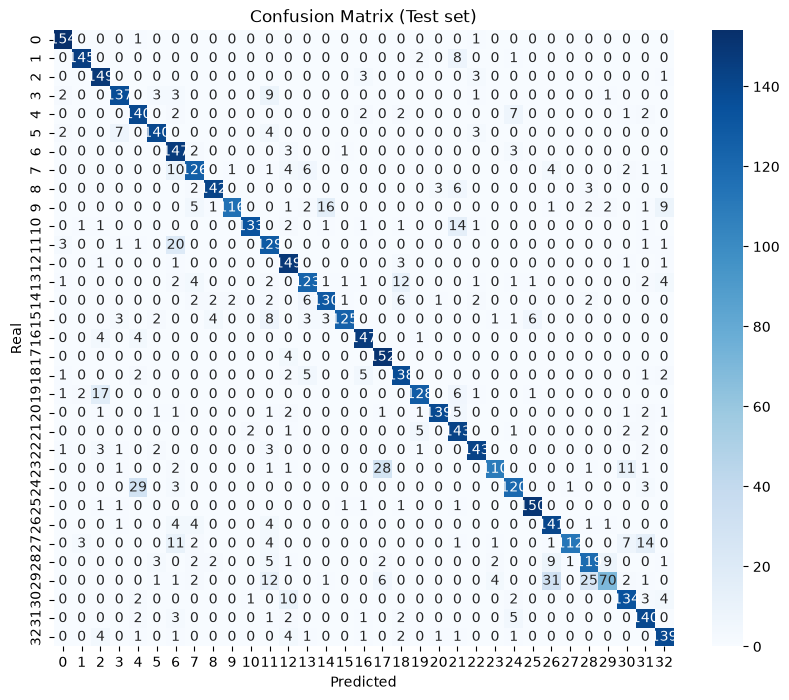

In [44]:
cm = confusion_matrix( y_test, y_pred)
plt.figure( figsize=(10, 8))
sns.heatmap( cm, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix (Test set)")
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.show()

## Loss + Accuracy curves

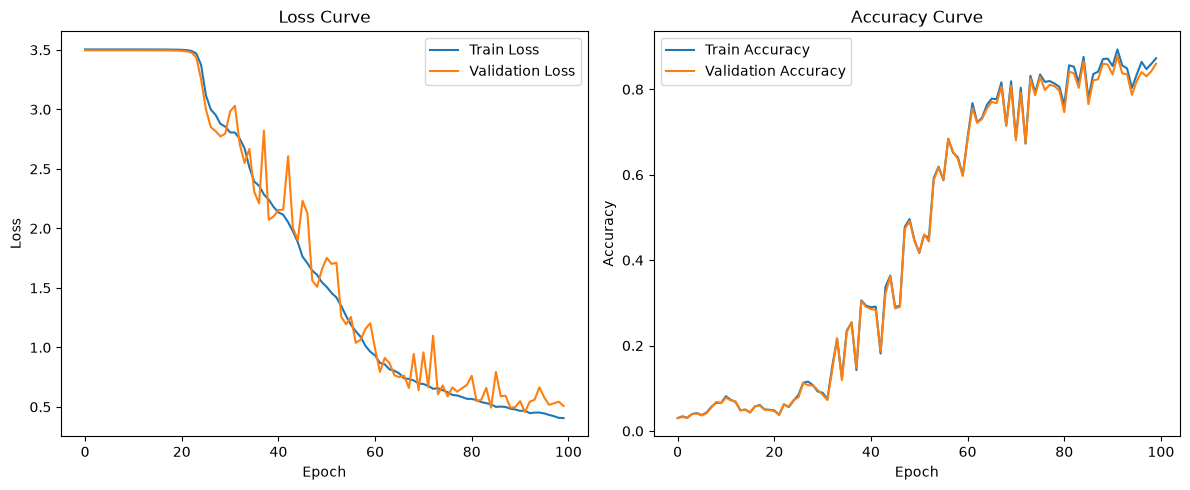

In [45]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(train_losses, label="Train Loss")
ax1.plot(val_losses, label="Validation Loss")
ax1.set_title("Loss Curve")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.legend()

ax2.plot(train_accuracies, label="Train Accuracy")
ax2.plot(val_accuracies, label="Validation Accuracy")
ax2.set_title("Accuracy Curve")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.legend()

plt.tight_layout()
plt.show()